In [1]:
#Importing needed libraries
import librosa
import numpy as np
import matplotlib.pyplot as plt
import librosa.display
from IPython.display import Audio
import os
import glob
import random

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import LabelEncoder

import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix

random.seed(123)
np.random.seed(123)
tf.random.set_seed(123)

In [2]:
#Dataset preparation on an existing dataset
dataset_dir = "./dataset"
words = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]

all_recordings = []
speakers_set = set()

for word in words:
    word_folder = os.path.join(dataset_dir, word)
    audio_files = glob.glob(os.path.join(word_folder, "*.wav"))
    
    random.shuffle(audio_files)
    selected_files = audio_files[:3500]
    
    for file_path in selected_files:
        file_name = os.path.basename(file_path)
        
        speaker_id = file_name.split("_nohash_")[0]
        speakers_set.add(speaker_id)
        
        all_recordings.append({
            "path": file_path,
            "word": word,
            "speaker": speaker_id
        })

unique_speakers = list(speakers_set)
random.shuffle(unique_speakers)

split_point = int(0.8 * len(unique_speakers))
train_speakers = set(unique_speakers[:split_point])
test_speakers = set(unique_speakers[split_point:])

train_data = []
test_data = []

for sample in all_recordings:
    if sample["speaker"] in train_speakers:
        train_data.append(sample)
    else:
        test_data.append(sample)

sample_audio_path = all_recordings[0]["path"]
audio_signal, sample_rate = librosa.load(sample_audio_path, sr=None)
overlap = train_speakers.intersection(test_speakers)

print("=== Dataset preparation summary === ")
print("Dataset name: Google Speech Commands Dataset v0.02")
print("10 selected words:", words)
print(f"Sampling Frequency: {sample_rate} Hz")
print(f"Total number of speakers: {len(unique_speakers)}")
print(f"total Number of recordings: {len(all_recordings)}")
print(f"Train set size: {len(train_data)} recordings ({len(train_speakers)} speakers)")
print(f"Test set size: {len(test_data)} recordings ({len(test_speakers)} speakers)")
print(f"Speaker overlap count: {len(overlap)} overlaps")

print("\n=== Recordings amount per word ===")
print(f"{'Word':<10} | {'Train':<10} | {'Test':<10} | {'Total':<10}")
print("-" * 45)

for word in words:
    total_count = sum(1 for item in all_recordings if item["word"] == word)
    train_count = sum(1 for item in train_data if item["word"] == word)
    test_count = sum(1 for item in test_data if item["word"] == word)
    print(f"{word:<10} | {train_count:<10} | {test_count:<10} | {total_count:<10}")

=== Dataset preparation summary === 
Dataset name: Google Speech Commands Dataset v0.02
10 selected words: ['yes', 'no', 'up', 'down', 'left', 'right', 'on', 'off', 'stop', 'go']
Sampling Frequency: 16000 Hz
Total number of speakers: 2480
total Number of recordings: 35000
Train set size: 27908 recordings (1984 speakers)
Test set size: 7092 recordings (496 speakers)
Speaker overlap count: 0 overlaps

=== Recordings amount per word ===
Word       | Train      | Test       | Total     
---------------------------------------------
yes        | 2781       | 719        | 3500      
no         | 2810       | 690        | 3500      
up         | 2795       | 705        | 3500      
down       | 2772       | 728        | 3500      
left       | 2800       | 700        | 3500      
right      | 2772       | 728        | 3500      
on         | 2803       | 697        | 3500      
off        | 2789       | 711        | 3500      
stop       | 2793       | 707        | 3500      
go         | 279

Sample audio path: ./dataset\yes\b69002d4_nohash_0.wav
Word Label: 'yes'
Processed signal shape: (16000,)
Log-Mel spectrogram matrix dimension: (40, 101)


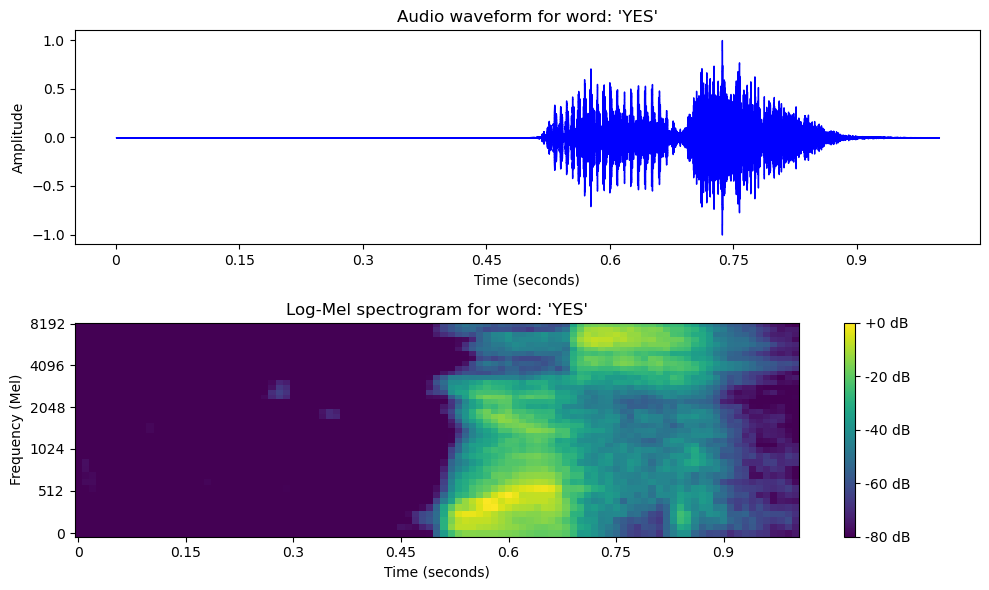

x_train Shape: (27908, 40, 101)
x_test Shape: (7092, 40, 101)


In [3]:
#Feature extraction for further use in a model
sample_rate = 16000
duration = 1.0
target_length = int(sample_rate * duration)

n_fft = 512
hop_length = 160
n_mels = 40
win_length = 512

def extract_log_mel_spectrogram(audio_path):
    y, sr = librosa.load(audio_path, sr=sample_rate)
    
    if len(y) < target_length:
        pad_width = target_length - len(y)
        y = np.pad(y, (0, pad_width), mode='constant')
    else:
        y = y[:target_length]
        
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sample_rate,
        n_fft=n_fft,
        hop_length=hop_length,
        win_length=win_length,
        window='hann',
        n_mels=n_mels
    )
    
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    
    return y, log_mel_spec

sample_recording = train_data[0]
audio_path = sample_recording["path"]
word_label = sample_recording["word"]

signal, log_mel = extract_log_mel_spectrogram(audio_path)

print(f"Sample audio path: {audio_path}")
print(f"Word Label: '{word_label}'")
print(f"Processed signal shape: {signal.shape}")
print(f"Log-Mel spectrogram matrix dimension: {log_mel.shape}")

fig, ax = plt.subplots(2, 1, figsize=(10, 6))

librosa.display.waveshow(signal, sr=sample_rate, ax=ax[0], color='b')
ax[0].set_title(f"Audio waveform for word: '{word_label.upper()}'")
ax[0].set_xlabel("Time (seconds)")
ax[0].set_ylabel("Amplitude")

img = librosa.display.specshow(
    log_mel, 
    sr=sample_rate, 
    hop_length=hop_length, 
    x_axis='time', 
    y_axis='mel', 
    ax=ax[1], 
    cmap='viridis'
)
fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
ax[1].set_title(f"Log-Mel spectrogram for word: '{word_label.upper()}'")
ax[1].set_xlabel("Time (seconds)")
ax[1].set_ylabel("Frequency (Mel)")

plt.tight_layout()
plt.show()

def extract_dataset_features(dataset):
    x_data = []
    y_data = []
    
    for sample in dataset:
        _, feat = extract_log_mel_spectrogram(sample["path"])
        x_data.append(feat)
        y_data.append(sample["word"])
        
    return np.array(x_data), np.array(y_data)

x_train, y_train = extract_dataset_features(train_data)
x_test, y_test = extract_dataset_features(test_data)

print(f"x_train Shape: {x_train.shape}")
print(f"x_test Shape: {x_test.shape}")

In [4]:
#Creating the model
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

x_train_cnn = x_train[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

input_shape = (40, 101, 1)
num_classes = len(words)

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

batch_size = 64
epochs = 20

history = model.fit(
    x_train_cnn, y_train_encoded,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(x_test_cnn, y_test_encoded)
)

test_loss, test_acc = model.evaluate(x_test_cnn, y_test_encoded, verbose=0)
print(f"\nFinal test accuracy: {test_acc * 100:.2f}%")
print(f"Final test loss: {test_loss:.4f}")

model.save("speech_recognition_model.keras")

C:\Users\Lenovo\anaconda3\envs\nlp_vu\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 38, 99, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 38, 99, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 19, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 19, 49, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 17, 47, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 17, 47, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 23, 64)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 8, 23, 64)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 6, 21, 64)           │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 6, 21, 64)           │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 3, 10, 64)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 3, 10, 64)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1920)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         245,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 303,562 (1.16 MB)

 Trainable params: 303,242 (1.16 MB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 148s 326ms/step - accuracy: 0.3901 - loss: 1.7413 - val_accuracy: 0.4876 - val_loss: 1.5653
Epoch 2/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 141s 321ms/step - accuracy: 0.6624 - loss: 0.9458 - val_accuracy: 0.4365 - val_loss: 2.1548
Epoch 3/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 141s 323ms/step - accuracy: 0.7540 - loss: 0.7002 - val_accuracy: 0.7403 - val_loss: 0.8003
Epoch 4/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 140s 321ms/step - accuracy: 0.8063 - loss: 0.5556 - val_accuracy: 0.8511 - val_loss: 0.4462
Epoch 5/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 142s 325ms/step - accuracy: 0.8367 - loss: 0.4700 - val_accuracy: 0.8222 - val_loss: 0.5886
Epoch 6/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 140s 320ms/step - accuracy: 0.8568 - loss: 0.4217 - val_accuracy: 0.9052 - val_loss: 0.2952
Epoch 7/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 144s 323ms/step - accuracy: 0.8733 - loss: 0.3746 - val_accuracy: 0.9146 - val_loss: 0.2674
Epoch 8/20
437/437 ━━━━━━━━━━━━━━━━━━━━ 141s 324ms/step - accuracy: 0.8834 -

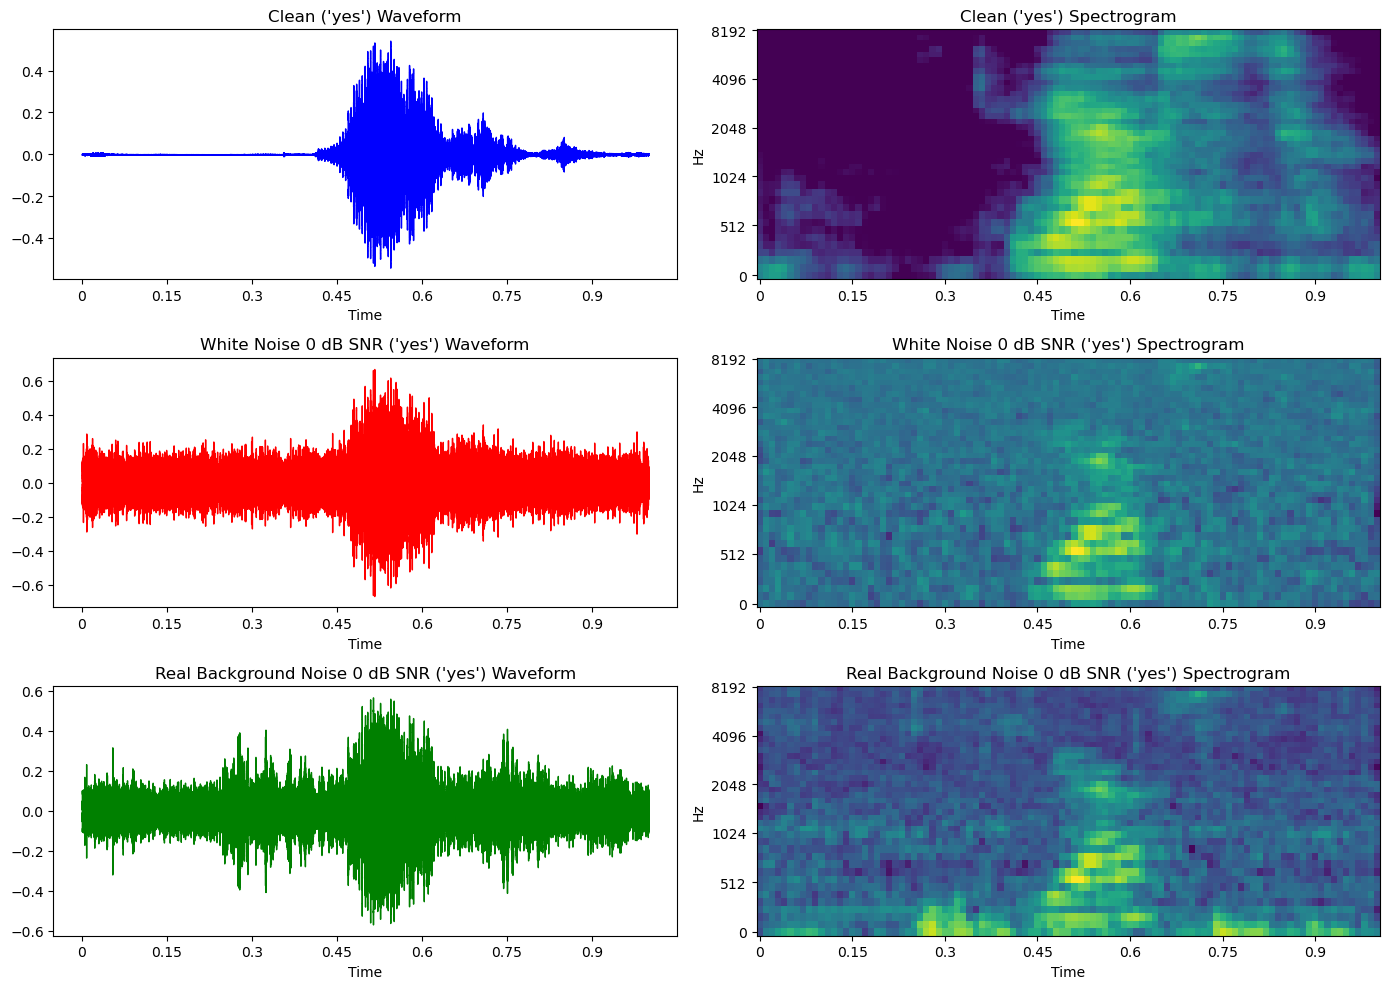


=== Summary of test accuracies (%) ===
Condition                 | Clean    | 30 dB    | 20 dB    | 10 dB    | 0 dB    
---------------------------------------------------------------------------
Clean Baseline            | 94.44    | N/A      | N/A      | N/A      | N/A     
Synthetic White Noise     | N/A      | 93.02    | 88.45    | 78.92    | 58.81   
Real Background Noise     | N/A      | 93.39    | 91.41    | 84.55    | 65.98   


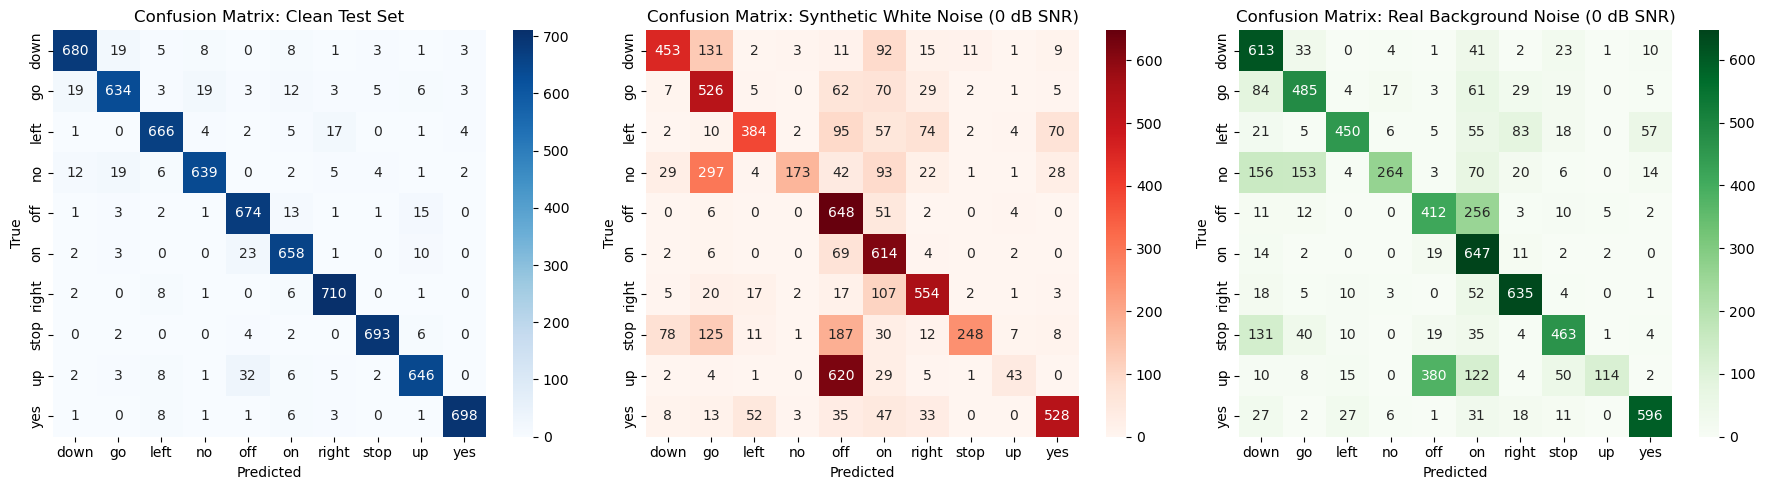

In [7]:
#Testing the model's performance by adding noises to audio samples
random.seed(123)
np.random.seed(123)

bg_noise_folder = os.path.join(dataset_dir, "_background_noise_")
bg_noise_file = os.path.join(bg_noise_folder, "exercise_bike.wav")
bg_audio = librosa.load(bg_noise_file, sr=sample_rate)[0]

if len(bg_audio) < target_length:
    bg_audio = np.tile(bg_audio, int(np.ceil(target_length / len(bg_audio))))

start = np.random.randint(0, len(bg_audio) - target_length + 1)
real_noise = bg_audio[start:start + target_length]

white_noise = np.random.normal(0, 1.0, target_length)

def compute_log_mel(y_sig):
    mel = librosa.feature.melspectrogram(
        y=y_sig, sr=sample_rate, n_fft=n_fft,
        hop_length=hop_length, win_length=win_length,
        window='hann', n_mels=n_mels
    )
    return librosa.power_to_db(mel, ref=np.max)

def add_noise_at_snr(signal, noise, target_snr_db):
    s_p = np.mean(signal ** 2)
    n_p = np.mean(noise ** 2)
    if s_p == 0 or n_p == 0:
        return signal
    scaling = np.sqrt((s_p / (10 ** (target_snr_db / 10.0))) / n_p)
    return signal + (noise * scaling)

test_signals = []

for sample in test_data:
    y, _ = librosa.load(sample["path"], sr=sample_rate)
    y = np.pad(y, (0, max(0, target_length - len(y))), mode='constant')[:target_length]
    test_signals.append(y)

sample_word = test_data[0]["word"]
y_c = test_signals[0]
y_w = add_noise_at_snr(y_c, white_noise, 0)
y_r = add_noise_at_snr(y_c, real_noise, 0)

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
plots = [(y_c, f"Clean ('{sample_word}')", 'b'),
         (y_w, f"White Noise 0 dB SNR ('{sample_word}')", 'r'),
         (y_r, f"Real Background Noise 0 dB SNR ('{sample_word}')", 'g')]

for i, (sig, title, color) in enumerate(plots):
    librosa.display.waveshow(sig, sr=sample_rate, ax=axes[i, 0], color=color)
    axes[i, 0].set_title(f"{title} Waveform")
    librosa.display.specshow(compute_log_mel(sig), sr=sample_rate, hop_length=hop_length, x_axis='time', y_axis='mel', ax=axes[i, 1], cmap='viridis')
    axes[i, 1].set_title(f"{title} Spectrogram")

plt.tight_layout()
plt.show()

snr_levels = [30, 20, 10, 0]
results = {'Clean': 0.0, 'White': {}, 'Real': {}}
preds_dict = {'Clean': None, 'White': {}, 'Real': {}}

clean_mels = np.array([compute_log_mel(s) for s in test_signals])[..., np.newaxis]
clean_preds = np.argmax(model.predict(clean_mels, verbose=0), axis=1)
results['Clean'] = accuracy_score(y_test_encoded, clean_preds) * 100
preds_dict['Clean'] = clean_preds

noise_sources = {'White': white_noise, 'Real': real_noise}

for n_type, noise in noise_sources.items():
    for snr in snr_levels:
        noisy_mels = np.array([compute_log_mel(add_noise_at_snr(s, noise, snr)) for s in test_signals])[..., np.newaxis]
        preds = np.argmax(model.predict(noisy_mels, verbose=0), axis=1)
        results[n_type][snr] = accuracy_score(y_test_encoded, preds) * 100
        preds_dict[n_type][snr] = preds

print("\n=== Summary of test accuracies (%) ===")
print(f"{'Condition':<25} | {'Clean':<8} | {'30 dB':<8} | {'20 dB':<8} | {'10 dB':<8} | {'0 dB':<8}")
print("-" * 75)
print(f"{'Clean Baseline':<25} | {results['Clean']:<8.2f} | {'N/A':<8} | {'N/A':<8} | {'N/A':<8} | {'N/A':<8}")
print(f"{'Synthetic White Noise':<25} | {'N/A':<8} | {results['White'][30]:<8.2f} | {results['White'][20]:<8.2f} | {results['White'][10]:<8.2f} | {results['White'][0]:<8.2f}")
print(f"{'Real Background Noise':<25} | {'N/A':<8} | {results['Real'][30]:<8.2f} | {results['Real'][20]:<8.2f} | {results['Real'][10]:<8.2f} | {results['Real'][0]:<8.2f}")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
class_names = label_encoder.classes_
cms = [(preds_dict['Clean'], "Clean Test Set", 'Blues'),
       (preds_dict['White'][0], "Synthetic White Noise (0 dB SNR)", 'Reds'),
       (preds_dict['Real'][0], "Real Background Noise (0 dB SNR)", 'Greens')]

for i, (pred, title, cmap) in enumerate(cms):
    sns.heatmap(confusion_matrix(y_test_encoded, pred), annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, ax=ax[i], cmap=cmap)
    ax[i].set_title(f"Confusion Matrix: {title}")
    ax[i].set_xlabel("Predicted")
    ax[i].set_ylabel("True")

plt.tight_layout()
plt.show()